<a href="https://colab.research.google.com/github/Abhi712-ui/lis501-ipynb-files/blob/main/Week_5_Text_Similarity_and_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LIS 501 · Week 5 (Text Similarity & Classification)

## From word counts to text classification

**Our question:** Can the words in a new post help us decide which discussion group it belongs to?

We will use one rule throughout: **find the most similar labeled post, then borrow its label.** Bag-of-Words and TF-IDF give us two ways to represent the posts before comparing them.

| Activity
|---
| Explore 20 Newsgroups and read real posts · Exercise 1
| Compare word counts and TF-IDF weights
| Find a similar post and borrow its label · Exercise 2
| Build two classifiers and inspect their predictions
| Wrap-up

The exercise time is included. Run the import and dataset-download cells before class. A standard Colab CPU runtime is sufficient.

# 1. Meet the dataset

**20 Newsgroups contains real Usenet discussion posts from 20 forums.** A forum is a named discussion group. Each post has one forum label, even when its content touches several subjects. [1]

We first load the training collection and put it in a table. Each row contains one post and its category name. The loader uses filters to remove headers, footers, and quoted text; our table filter removes bodies that become blank. The first download needs an internet connection. [1]

The code is supplied. Focus on the table it creates and the texts we will read.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

pd.set_option('display.max_colwidth', 100)

In [ ]:
news = fetch_20newsgroups(
    subset='train', remove=('headers', 'footers', 'quotes'), random_state=42
)
all_posts = pd.DataFrame({
    'text': news.data,
    'category': np.array(news.target_names)[news.target],
})
all_posts = all_posts[all_posts['text'].str.strip() != ''].reset_index(drop=True)
print('Table shape (rows, columns):', all_posts.shape)

Table shape (rows, columns): (11014, 2)


## What do people discuss?

This chart names all 20 categories and counts their nonblank training posts.

**Look together:** Which groups seem easy to distinguish? Which groups might use similar words?

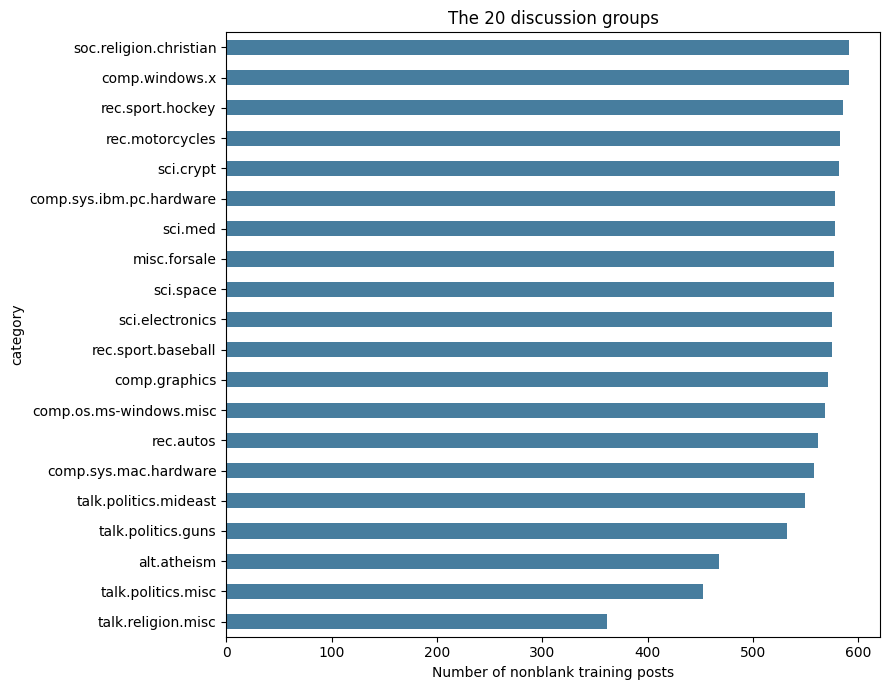

In [ ]:
category_counts = all_posts['category'].value_counts().sort_values()
category_counts.plot.barh(figsize=(9, 7), color='#477D9E')
plt.title('The 20 discussion groups')
plt.xlabel('Number of nonblank training posts')
plt.tight_layout()
plt.show()

## Work with four familiar groups

We will build our models with **computer graphics, baseball, hockey, and space**. Baseball and hockey give us two groups that may share words such as *team* and *game*.

The next cell selects those rows. The count beside each group tells us how many training examples we have for that label.

In [ ]:
categories = ['comp.graphics', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.space']
train_df = all_posts[all_posts['category'].isin(categories)].reset_index(drop=True)
display(train_df['category'].value_counts().sort_index())
print('Training table shape:', train_df.shape)

,count
category,
comp.graphics,571
rec.sport.baseball,575
rec.sport.hockey,585
sci.space,577


Training table shape: (2308, 2)


## Read the documents before counting words

Here are four selected training posts, one from each category. The preview shows their first few words. We will keep using these same four posts when we inspect counts and TF-IDF.

In [ ]:
example_rows = [128, 499, 1543, 577]
examples = train_df.loc[example_rows, ['category', 'text']].reset_index(drop=True)
display(examples)

,category,text
0,comp.graphics,"Howdy all,\n\n\tI was wondering if people could e-mail me their opinions on\nthe various graphic..."
1,rec.sport.baseball,\n\n\n\n\nThese people were very silly. Any team that gets to the World Series\ncan win the Wor...
2,rec.sport.hockey,"In Detroit, the octopus is a symbol from the old days of the league. In\nthe era of the Original..."
3,sci.space,"Hello everyone,\n\n\tI was hoping someone could help me out. I'm writing a program\n\tfor my as..."


## Exercise 1 · Find the clues

Change `example_number` to **0, 1, 2, or 3** to read a post in full. Read two of the examples.

- Which two words or phrases help you recognize each post's category?
- Which words could also appear in another category?

**Your notes:** My category clues are ________. Words another group might share are ________.

In [ ]:
example_number = 0
example = examples.iloc[example_number]
print('Category:', example['category'])
print(example['text'])

Category: comp.graphics
Howdy all,

	I was wondering if people could e-mail me their opinions on
the various graphics viewers available for MS-Windows 3.x...  I'm
working on a project to set up our scanner and write documentation on
how to use it and it would be nice to have a snazzy image viewer 
to look at (and maybe even edit?) the image you just scanned.

The file formats I'm looking for:

GIF
JPEG
TIFF
PCX
whatever other 'major' file formats there are.

Thanks a lot for your help

Grant



## How much text does one post contain?

`word_count` counts whitespace-separated pieces for a quick length check. In the summary, **50% is the median**: half the posts are at or below that length. `max` is the longest post.

**Discuss:** How might a very short post be harder to classify than a longer one?

In [ ]:
train_df['word_count'] = train_df['text'].str.split().str.len()
display(train_df['word_count'].describe().round(1))

,word_count
count,2308.0
mean,175.7
std,522.4
min,1.0
25%,38.0
50%,73.0
75%,147.0
max,11251.0


# 2. Represent the posts with words

## Bag-of-Words: count each word

A **document–term table** has one row per post and one column per vocabulary term. Each cell counts how often that term occurs in that post.

`CountVectorizer` lowercases the text, splits it into terms, and counts them. Here it also removes a built-in list of common English words. `fit_transform()` learns the vocabulary from our training posts and fills their counts. [2]

In [ ]:
count_vectorizer = CountVectorizer(stop_words='english')
train_counts = count_vectorizer.fit_transform(train_df['text'])
words = count_vectorizer.get_feature_names_out()
print('Count table shape (posts, vocabulary terms):', train_counts.shape)

Count table shape (posts, vocabulary terms): (2308, 26982)


## Inspect a small part of the table

The full representation contains thousands of columns, so we display **our four example posts and eight words**. The models will use every vocabulary column.

**Read a cell:** A value of 4 under *team* means that the post uses that word four times. What do the baseball and hockey rows share?

In [ ]:
display_words = ['graphics', 'image', 'baseball', 'team', 'game', 'shuttle', 'orbit', 'ice']
small_counts = pd.DataFrame(train_counts[example_rows].toarray(), columns=words)
small_counts.index = examples['category']
display(small_counts[display_words])

,graphics,image,baseball,team,game,shuttle,orbit,ice
category,,,,,,,,
comp.graphics,1,2,0,0,0,0,0,0
rec.sport.baseball,0,0,2,4,1,0,0,0
rec.sport.hockey,0,0,0,1,1,0,0,1
sci.space,0,0,0,0,0,2,1,0


## TF-IDF: change counts into weights

TF-IDF gives more weight to terms that recur in a post and distinguish it within the training collection. The library also rescales each post's vector to a common length. [3]

We keep **the same posts and vocabulary columns**. The numbers in the cells change from counts to weights. Compare the two tables: do words with the same count always have the same weight?

`TfidfTransformer` takes the count table as its input.

In [ ]:
tfidf = TfidfTransformer()
train_tfidf = tfidf.fit_transform(train_counts)

In [ ]:
small_weights = pd.DataFrame(train_tfidf[example_rows].toarray(), columns=words)
small_weights.index = examples['category']
display(small_weights[display_words].round(3))

,graphics,image,baseball,team,game,shuttle,orbit,ice
category,,,,,,,,
comp.graphics,0.112,0.243,0.000,0.000,0.000,0.000,0.000,0.000
rec.sport.baseball,0.000,0.000,0.241,0.359,0.092,0.000,0.000,0.000
rec.sport.hockey,0.000,0.000,0.000,0.074,0.076,0.000,0.000,0.112
sci.space,0.000,0.000,0.000,0.000,0.000,0.322,0.151,0.000


# 3. Find a similar post

**Cosine similarity compares the pattern of word weights in two texts.** With our nonnegative representations, a higher score means a closer match in those features. A score of 0 means there are no shared retained terms. [4]

We will compare an invented new post with every training post. First, `transform()` puts it into the **fitted vocabulary and TF-IDF representation**.

Run the next two cells, then inspect the three best matches. Do any look familiar?

In [ ]:
new_post = 'The baseball team won the game with a home run.'
new_counts = count_vectorizer.transform([new_post])
new_tfidf = tfidf.transform(new_counts)

In [ ]:
similarities = cosine_similarity(new_tfidf, train_tfidf).ravel()
matches = train_df[['category', 'text']].copy()
matches['similarity'] = similarities
top_matches = matches.sort_values('similarity', ascending=False).head(3)
display(top_matches[['category', 'similarity', 'text']].round(3))

,category,similarity,text
499,rec.sport.baseball,0.255,\n\n\n\n\nThese people were very silly. Any team that gets to the World Series\ncan win the Wor...
650,rec.sport.baseball,0.233,Philadelphia at Chicago: Teams tied for 1st after Sunday\n Dick Redding battled Chet Brewer...
2200,comp.graphics,0.232,The real problem w/ the Stealth from what I've heard is that Diamond won't\ntell anyone how to p...


## Borrow the closest post's label

We now use a classification rule: **give the new post the category of its most similar training post**.

`idxmax()` finds the row with the highest score. Read that post and decide whether borrowing its label makes sense. A new text with no shared words cannot provide a meaningful match; the check below asks for another text in that case.

In [ ]:
if similarities.max() == 0:
    print('No shared words. Try a new post with words from the collection.')
else:
    closest_row = matches['similarity'].idxmax()
    print('Predicted category:', matches.loc[closest_row, 'category'])
    print('Closest training post:')
    print(matches.loc[closest_row, 'text'])

Predicted category: rec.sport.baseball
Closest training post:





These people were very silly.  Any team that gets to the World Series
can win the World Series, and anybody who ever expects a sweep is
crazy.  If you put the best team in baseball in the Series against
the worst team in baseball, the worst team would win at least a game
most of the time and very well could win the Series, though the odds
would certainly be against them.


## Exercise 2 · Make your own prediction

Change `new_post` to one sentence about **hockey or baseball**, then rerun the three cells above: represent it, find matches, and borrow a label.

1. Predict the category before running.
2. Read the closest post. Which shared words help explain the match?
3. Change one or two words. Does the closest match change?

**Your notes:** My sentence is ________. My predicted category is ________. The returned category is ________. The words supporting the match are ________.

# 4. Turn the rule into classification models

We have classified one new post. Now we will let scikit-learn apply the same rule to a collection of **held-out test posts**.

- **Training posts:** supply the vocabulary, IDF weights, and labeled examples.
- **Test posts:** provide new examples on which we check predictions.

We use the dataset's supplied train/test split and the same blank-body filter. Test texts use `transform()`, which keeps the training vocabulary and IDF fixed. [1, 7]

In [ ]:
test_news = fetch_20newsgroups(
    subset='test', categories=categories,
    remove=('headers', 'footers', 'quotes'), random_state=42,
)
test_df = pd.DataFrame({
    'text': test_news.data,
    'category': np.array(test_news.target_names)[test_news.target],
})
test_df = test_df[test_df['text'].str.strip() != ''].reset_index(drop=True)
print('Test posts:', len(test_df))

Test posts: 1535


In [ ]:
test_counts = count_vectorizer.transform(test_df['text'])
test_tfidf = tfidf.transform(test_counts)

## Model 1: use word counts

`KNeighborsClassifier` finds nearby labeled examples. We choose **one neighbor** and **cosine** for the comparison. `fit()` stores the labeled training examples; `predict()` finds a match for each test post and returns that match's category. [5]

The model calls its comparison *cosine distance*. A smaller distance corresponds to a higher cosine similarity: **distance = 1 − similarity**.

In [ ]:
count_model = KNeighborsClassifier(n_neighbors=1, metric='cosine')
count_model.fit(train_counts, train_df['category'])
count_predictions = count_model.predict(test_counts)

## Model 2: use TF-IDF weights

Keep the same training posts, test posts, labels, and nearest-neighbor rule. Change the representation to TF-IDF.

**Predict:** Could changing the word weights change which post is the nearest neighbor?

In [ ]:
tfidf_model = KNeighborsClassifier(n_neighbors=1, metric='cosine')
tfidf_model.fit(train_tfidf, train_df['category'])
tfidf_predictions = tfidf_model.predict(test_tfidf)

## How often does each model match the observed label?

**Accuracy** is the fraction of test posts assigned their observed forum label. We show it as a percentage. Both results use the same test posts. [6]

The second table shows a few individual predictions. Ask where the predicted and observed categories agree.

If a post has no shared retained words, or several matches tie, its chosen label may be uninformative. Such nonblank test posts remain in these scores.

In [ ]:
count_accuracy = accuracy_score(test_df['category'], count_predictions)
tfidf_accuracy = accuracy_score(test_df['category'], tfidf_predictions)
accuracy_comparison = pd.DataFrame({
    'Representation': ['Word counts', 'TF-IDF'],
    'Correctly classified (%)': [100 * count_accuracy, 100 * tfidf_accuracy],
})
display(accuracy_comparison.round(1))

,Representation,Correctly classified (%)
0,Word counts,73.9
1,TF-IDF,81.2


In [ ]:
prediction_table = pd.DataFrame({
    'observed': test_df['category'],
    'predicted': tfidf_predictions,
    'text': test_df['text'],
})
display(prediction_table[['observed', 'predicted']].head())

,observed,predicted
0,sci.space,sci.space
1,rec.sport.baseball,comp.graphics
2,rec.sport.hockey,rec.sport.hockey
3,sci.space,sci.space
4,rec.sport.baseball,rec.sport.baseball


## Read one error: what does “arm” mean?

The next cells show **test post 97** and the training post that the TF-IDF model selected as its closest match. Read the two texts together.

What does *arm* refer to in each post? How can matching the same word create a misleading match?

In [ ]:
mistake_number = 97
print(prediction_table.loc[mistake_number, ['observed', 'predicted']])
print(prediction_table.loc[mistake_number, 'text'])

observed     rec.sport.baseball
predicted         comp.graphics
Name: 97, dtype: object
Jason Lee asks:

You must have heard wrong.  His arm is still sore.  He hasn't gone on the DL,
but he may.  Managmenet is treating him as a day-to-day situation.  

His doctors thought that he was ready, and they had him throw in
Colorado, but his arm wasn't up to the strain.  He is throwing every day,
but he's just not quite ready to pitch full strength yet.

(This is based on an interview that he gave on WFAN NY radio on Thursday,
4/23)


In [ ]:
# This is the fitted model's closest training post for test post 97.
print('Closest training post:', train_df.loc[1366, 'category'])
print(train_df.loc[1366, 'text'][:400])

Closest training post: comp.graphics

Acorn Replay running on a 25MHz ARM 3 processor (the ARM 3 is about 20% slower
than the ARM 6) does this in software (off a standard CD-ROM). 16 bit colour at
about the same resolution (so what if the computer only has 8 bit colour
support, real-time dithering too...). The 3D0/O is supposed to have a couple of
DSPs - the ARM being used for housekeeping.


A 25MHz ARM 6xx should clock around 20 AR


# Wrap-up

Complete these sentences in your own words:

- Bag-of-Words represents a post by ________.
- TF-IDF changes that representation by ________.
- Cosine similarity helps us ________.
- Our nearest-neighbor classifier predicts a category by ________.

**One connected workflow:** represent the text, compare it with labeled examples, predict a label, and read some successes and errors.

## Sources

1. [20 Newsgroups: documents, labels, metadata removal, and the train/test split](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset)
2. [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
3. [TfidfTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html)
4. [Cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
5. [Nearest-neighbor classification](https://scikit-learn.org/stable/modules/neighbors.html#nearest-neighbors-classification) · [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
6. [Accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)
7. [Keeping training and evaluation data separate](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)